In [222]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt


In [223]:
# -----------------------------
# Load dataset
# -----------------------------
file_path = "Z:/Machine_learning Dr. Vimina/Machine Learning 2026/BCA H 2026/ML Lab Programs/Titanic-Dataset.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
print(data.head())

Original Dataset
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

In [224]:
print(data.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [225]:
# ---------------------------------------
# Display Dataset Information
# ---------------------------------------

print("\nDataset Information")
print(data.info())


Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [226]:
# ---------------------------------------
# Drop Unnecessary Columns
# ---------------------------------------

data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [227]:
# ---------------------------------------
# Check Missing Values
# ---------------------------------------

print("\nMissing Values")
print(data.isnull().sum())


Missing Values
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [228]:
# ---------------------------------------
# Handle Missing Values
# ---------------------------------------

# Numerical column
age_imputer = SimpleImputer(strategy="mean")
data["Age"] = age_imputer.fit_transform(data[["Age"]])

# Categorical column
embarked_imputer = SimpleImputer(strategy="most_frequent")
data["Embarked"] = embarked_imputer.fit_transform(data[["Embarked"]]).ravel()


In [229]:
# ---------------------------------------
# Check Missing Values again
# ---------------------------------------

print("\nMissing Values")
print(data.isnull().sum())


Missing Values
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [230]:
# ---------------------------------------
# Encode Categorical Variables
# ---------------------------------------

encoder = LabelEncoder()

data["Sex"] = encoder.fit_transform(data["Sex"])
data["Embarked"] = encoder.fit_transform(data["Embarked"])

print("\nAfter Encoding")
print(data.head())



After Encoding
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


In [231]:
# ---------------------------------------
# Separate Features and remove Target
# ---------------------------------------

X = data.drop("Survived", axis=1)
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.000000,1,0,7.2500,2
1,1,0,38.000000,1,0,71.2833,0
2,3,0,26.000000,0,0,7.9250,2
3,1,0,35.000000,1,0,53.1000,2
4,3,1,35.000000,0,0,8.0500,2
...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,2
887,1,0,19.000000,0,0,30.0000,2
888,3,0,29.699118,1,2,23.4500,2
889,1,1,26.000000,0,0,30.0000,0


In [232]:
# ---------------------------------------
# Feature Scaling
# ---------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [233]:
#Create the K-Means model
kmeans = KMeans(n_clusters=2,random_state=42,n_init=10)

In [234]:
# Perform clustering
y_kmeans = kmeans.fit_predict(X_scaled)

In [235]:
#Display cluster assignments
print("\nCluster assignments:")
print(y_kmeans)


Cluster assignments:
[0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 1 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 0
 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0
 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 1 1
 1 0 0 1 1 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1
 0 1 1 1 0 0 0 0 0 1 1 1 0 1 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 1 1
 0 1 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1
 1 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 1 0 1 0 0 0
 0 1 0 1 0 1 0 0 1 1 0 0 1 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 

In [236]:
#Display cluster centroids
print("\nCluster centroids (standardized feature space):")
print(kmeans.cluster_centers_)


Cluster centroids (standardized feature space):
[[ 0.53048258  0.07092655 -0.23834678  0.03261954  0.00345836 -0.34061123
   0.13683033]
 [-1.45548371 -0.194601    0.65395145 -0.08949816 -0.00948869  0.93453418
  -0.37542102]]


In [237]:
#Count samples in each cluster
print("\nNumber of samples in each cluster:")

for cluster in range(2):
    count = np.sum(y_kmeans == cluster)
    print(f"Cluster {cluster}: {count} samples")


Number of samples in each cluster:
Cluster 0: 653 samples
Cluster 1: 238 samples


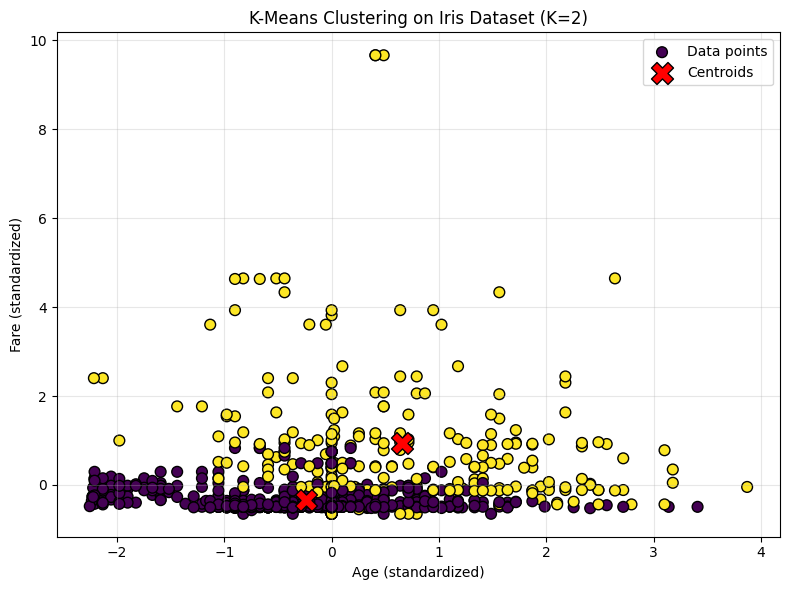

In [238]:
# 10. Visualize the clusters
# Use petal length and petal width for the plot

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 5],
    c=y_kmeans,
    cmap="viridis",
    s=60,
    edgecolor="black",
    label="Data points"
)

# Plot the centroids
centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 2],
    centroids[:, 5],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.xlabel("Age (standardized)")
plt.ylabel("Fare (standardized)")
plt.title("K-Means Clustering on Iris Dataset (K=2)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
